# 1-Epoch Learning Rate Schedule Comparison

In single-epoch training (`epochs=1`), each respondent group in the shuffled dataset is visited **only once**. Under standard `OneCycleLR` (which cosine-decays to `min_lr = max_lr / (25 * 1e4) = 2e-10`), the quadratic cosine tail starves the final third of the training data.

This notebook compares:
1. **Current `OneCycleLR` (default)**: cosine decay to `~0` (`2e-10`)
2. **`OneCycleLR` + 10% floor (`5e-6`)**: `final_div_factor=0.4` (`min_lr = 5e-6`)
3. **`OneCycleLR` + 20% floor (`1e-5`)**: `final_div_factor=0.2` (`min_lr = 1e-5`)
4. **`OneCycleLR` + 40% floor (`2e-5`)**: `final_div_factor=0.1` (`min_lr = 2e-5`)
5. **`OneCycleLR` + 50% floor (`2.5e-5`)**: `final_div_factor=0.08` (`min_lr = 2.5e-5`)
6. **Linear Decay + 10% floor (`5e-6`)**: linear warmup (300 steps) + linear decay to `5e-6`
7. **WSD (Warmup–Stable–Decay, 80% stable + 10% floor)**: warmup 300 steps, hold `5e-5` until 80% of epoch, then cosine decay to `5e-6` over the final 20%

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# 4B single-epoch schedule parameters
TOTAL_STEPS = 12_185
MAX_LR = 5e-5
WARMUP_STEPS = 300
PCT_START = WARMUP_STEPS / TOTAL_STEPS

def simulate_scheduler(make_sched_fn, total_steps=TOTAL_STEPS, max_lr=MAX_LR):
    param = torch.nn.Parameter(torch.zeros(1))
    opt = torch.optim.AdamW([param], lr=max_lr)
    sched = make_sched_fn(opt)
    lrs = []
    for _ in range(total_steps):
        lrs.append(sched.get_last_lr()[0])
        opt.step()
        sched.step()
    return np.array(lrs, dtype=np.float64)

def make_wsd_cosine(opt, total_steps=TOTAL_STEPS, warmup_steps=WARMUP_STEPS, stable_end_frac=0.80, min_lr_ratio=0.10):
    stable_end = int(round(stable_end_frac * total_steps))
    init_ratio = 1.0 / 25.0
    def lr_lambda(step):
        if step < warmup_steps:
            pct = step / max(1, warmup_steps)
            return init_ratio + (1.0 - init_ratio) * (1.0 - math.cos(math.pi * pct)) / 2.0
        if step < stable_end:
            return 1.0
        pct = (step - stable_end) / max(1, total_steps - stable_end)
        return min_lr_ratio + (1.0 - min_lr_ratio) * (1.0 + math.cos(math.pi * pct)) / 2.0
    return torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

def make_linear_with_floor(opt, total_steps=TOTAL_STEPS, warmup_steps=WARMUP_STEPS, min_lr_ratio=0.10):
    init_ratio = 1.0 / 25.0
    def lr_lambda(step):
        if step < warmup_steps:
            return init_ratio + (1.0 - init_ratio) * (step / max(1, warmup_steps))
        pct = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 1.0 - (1.0 - min_lr_ratio) * pct
    return torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

# In OneCycleLR: min_lr = max_lr / (div_factor * final_div_factor)
# With div_factor=25.0, a floor ratio `r = min_lr / max_lr` corresponds to `final_div_factor = 1 / (25 * r)`
schedules = {
    "1. OneCycleLR (current: min_lr=2e-10)": simulate_scheduler(
        lambda opt: torch.optim.lr_scheduler.OneCycleLR(
            opt, max_lr=MAX_LR, total_steps=TOTAL_STEPS, pct_start=PCT_START
        )
    ),
    "2. OneCycleLR + 10% floor (min_lr=5e-6)": simulate_scheduler(
        lambda opt: torch.optim.lr_scheduler.OneCycleLR(
            opt, max_lr=MAX_LR, total_steps=TOTAL_STEPS, pct_start=PCT_START,
            div_factor=25.0, final_div_factor=0.4
        )
    ),
    "3. OneCycleLR + 20% floor (min_lr=1e-5)": simulate_scheduler(
        lambda opt: torch.optim.lr_scheduler.OneCycleLR(
            opt, max_lr=MAX_LR, total_steps=TOTAL_STEPS, pct_start=PCT_START,
            div_factor=25.0, final_div_factor=0.2
        )
    ),
    "4. OneCycleLR + 40% floor (min_lr=2e-5)": simulate_scheduler(
        lambda opt: torch.optim.lr_scheduler.OneCycleLR(
            opt, max_lr=MAX_LR, total_steps=TOTAL_STEPS, pct_start=PCT_START,
            div_factor=25.0, final_div_factor=0.1
        )
    ),
    "5. OneCycleLR + 50% floor (min_lr=2.5e-5)": simulate_scheduler(
        lambda opt: torch.optim.lr_scheduler.OneCycleLR(
            opt, max_lr=MAX_LR, total_steps=TOTAL_STEPS, pct_start=PCT_START,
            div_factor=25.0, final_div_factor=0.08
        )
    ),
    "6. Linear Decay + 10% floor (min_lr=5e-6)": simulate_scheduler(
        lambda opt: make_linear_with_floor(opt, min_lr_ratio=0.10)
    ),
    "7. WSD (80% stable @ 5e-5 -> cosine to 5e-6)": simulate_scheduler(
        lambda opt: make_wsd_cosine(opt, stable_end_frac=0.80, min_lr_ratio=0.10)
    ),
}

steps = np.arange(1, TOTAL_STEPS + 1)
print(f"Simulated {len(schedules)} strategies over {TOTAL_STEPS:,} steps (max_lr={MAX_LR:.0e}, warmup={WARMUP_STEPS} steps).")

Simulated 7 strategies over 12,185 steps (max_lr=5e-05, warmup=300 steps).


In [2]:
# Compare LR at key milestones and share of cumulative LR budget per dataset third
t1 = TOTAL_STEPS // 3
t2 = (2 * TOTAL_STEPS) // 3
t80 = int(0.80 * TOTAL_STEPS)

rows = []
for name, lrs in schedules.items():
    total_area = lrs.sum()
    rows.append({
        "Strategy": name,
        "LR @ 33% (4,061)": f"{lrs[t1 - 1]:.2e}",
        "LR @ 50% (6,092)": f"{lrs[TOTAL_STEPS // 2 - 1]:.2e}",
        "LR @ 67% (8,123)": f"{lrs[t2 - 1]:.2e}",
        "LR @ 80% (9,748)": f"{lrs[t80 - 1]:.2e}",
        "LR @ 90% (10,966)": f"{lrs[int(0.90 * TOTAL_STEPS) - 1]:.2e}",
        "LR @ 100% (12,185)": f"{lrs[-1]:.2e}",
        "1st Third Share": f"{100 * lrs[:t1].sum() / total_area:.1f}%",
        "2nd Third Share": f"{100 * lrs[t1:t2].sum() / total_area:.1f}%",
        "Final Third Share": f"{100 * lrs[t2:].sum() / total_area:.1f}%",
        "Final 20% Share": f"{100 * lrs[t80:].sum() / total_area:.1f}%",
        "Mean LR in Final 1/3": f"{lrs[t2:].mean():.2e}",
    })

df_summary = pd.DataFrame(rows).set_index("Strategy")
display(df_summary)

,"LR @ 33% (4,061)","LR @ 50% (6,092)","LR @ 67% (8,123)","LR @ 80% (9,748)","LR @ 90% (10,966)","LR @ 100% (12,185)",1st Third Share,2nd Third Share,Final Third Share,Final 20% Share,Mean LR in Final 1/3
Strategy,,,,,,,,,,,
1. OneCycleLR (current: min_lr=2e-10),3.86e-05,2.60e-05,1.31e-05,5.01e-06,1.29e-06,2.00e-10,59.4%,34.6%,6.0%,1.4%,4.53e-06
2. OneCycleLR + 10% floor (min_lr=5e-6),3.98e-05,2.84e-05,1.68e-05,9.51e-06,6.16e-06,5.00e-06,54.6%,34.4%,11.0%,4.8%,9.08e-06
3. OneCycleLR + 20% floor (min_lr=1e-5),4.09e-05,3.08e-05,2.05e-05,1.40e-05,1.10e-05,1.00e-05,50.5%,34.3%,15.2%,7.6%,1.36e-05
4. OneCycleLR + 40% floor (min_lr=2e-5),4.32e-05,3.56e-05,2.78e-05,2.30e-05,2.08e-05,2.00e-05,44.1%,34.1%,21.8%,12.1%,2.27e-05
5. OneCycleLR + 50% floor (min_lr=2.5e-5),4.43e-05,3.80e-05,3.15e-05,2.75e-05,2.56e-05,2.50e-05,41.6%,34.0%,24.4%,13.9%,2.73e-05
6. Linear Decay + 10% floor (min_lr=5e-6),3.58e-05,2.81e-05,2.04e-05,1.42e-05,9.62e-06,5.00e-06,50.5%,34.1%,15.4%,7.0%,1.27e-05
7. WSD (80% stable @ 5e-5 -> cosine to 5e-6),5.00e-05,5.00e-05,5.00e-05,5.00e-05,2.75e-05,5.00e-06,35.8%,37.1%,27.1%,12.3%,3.65e-05


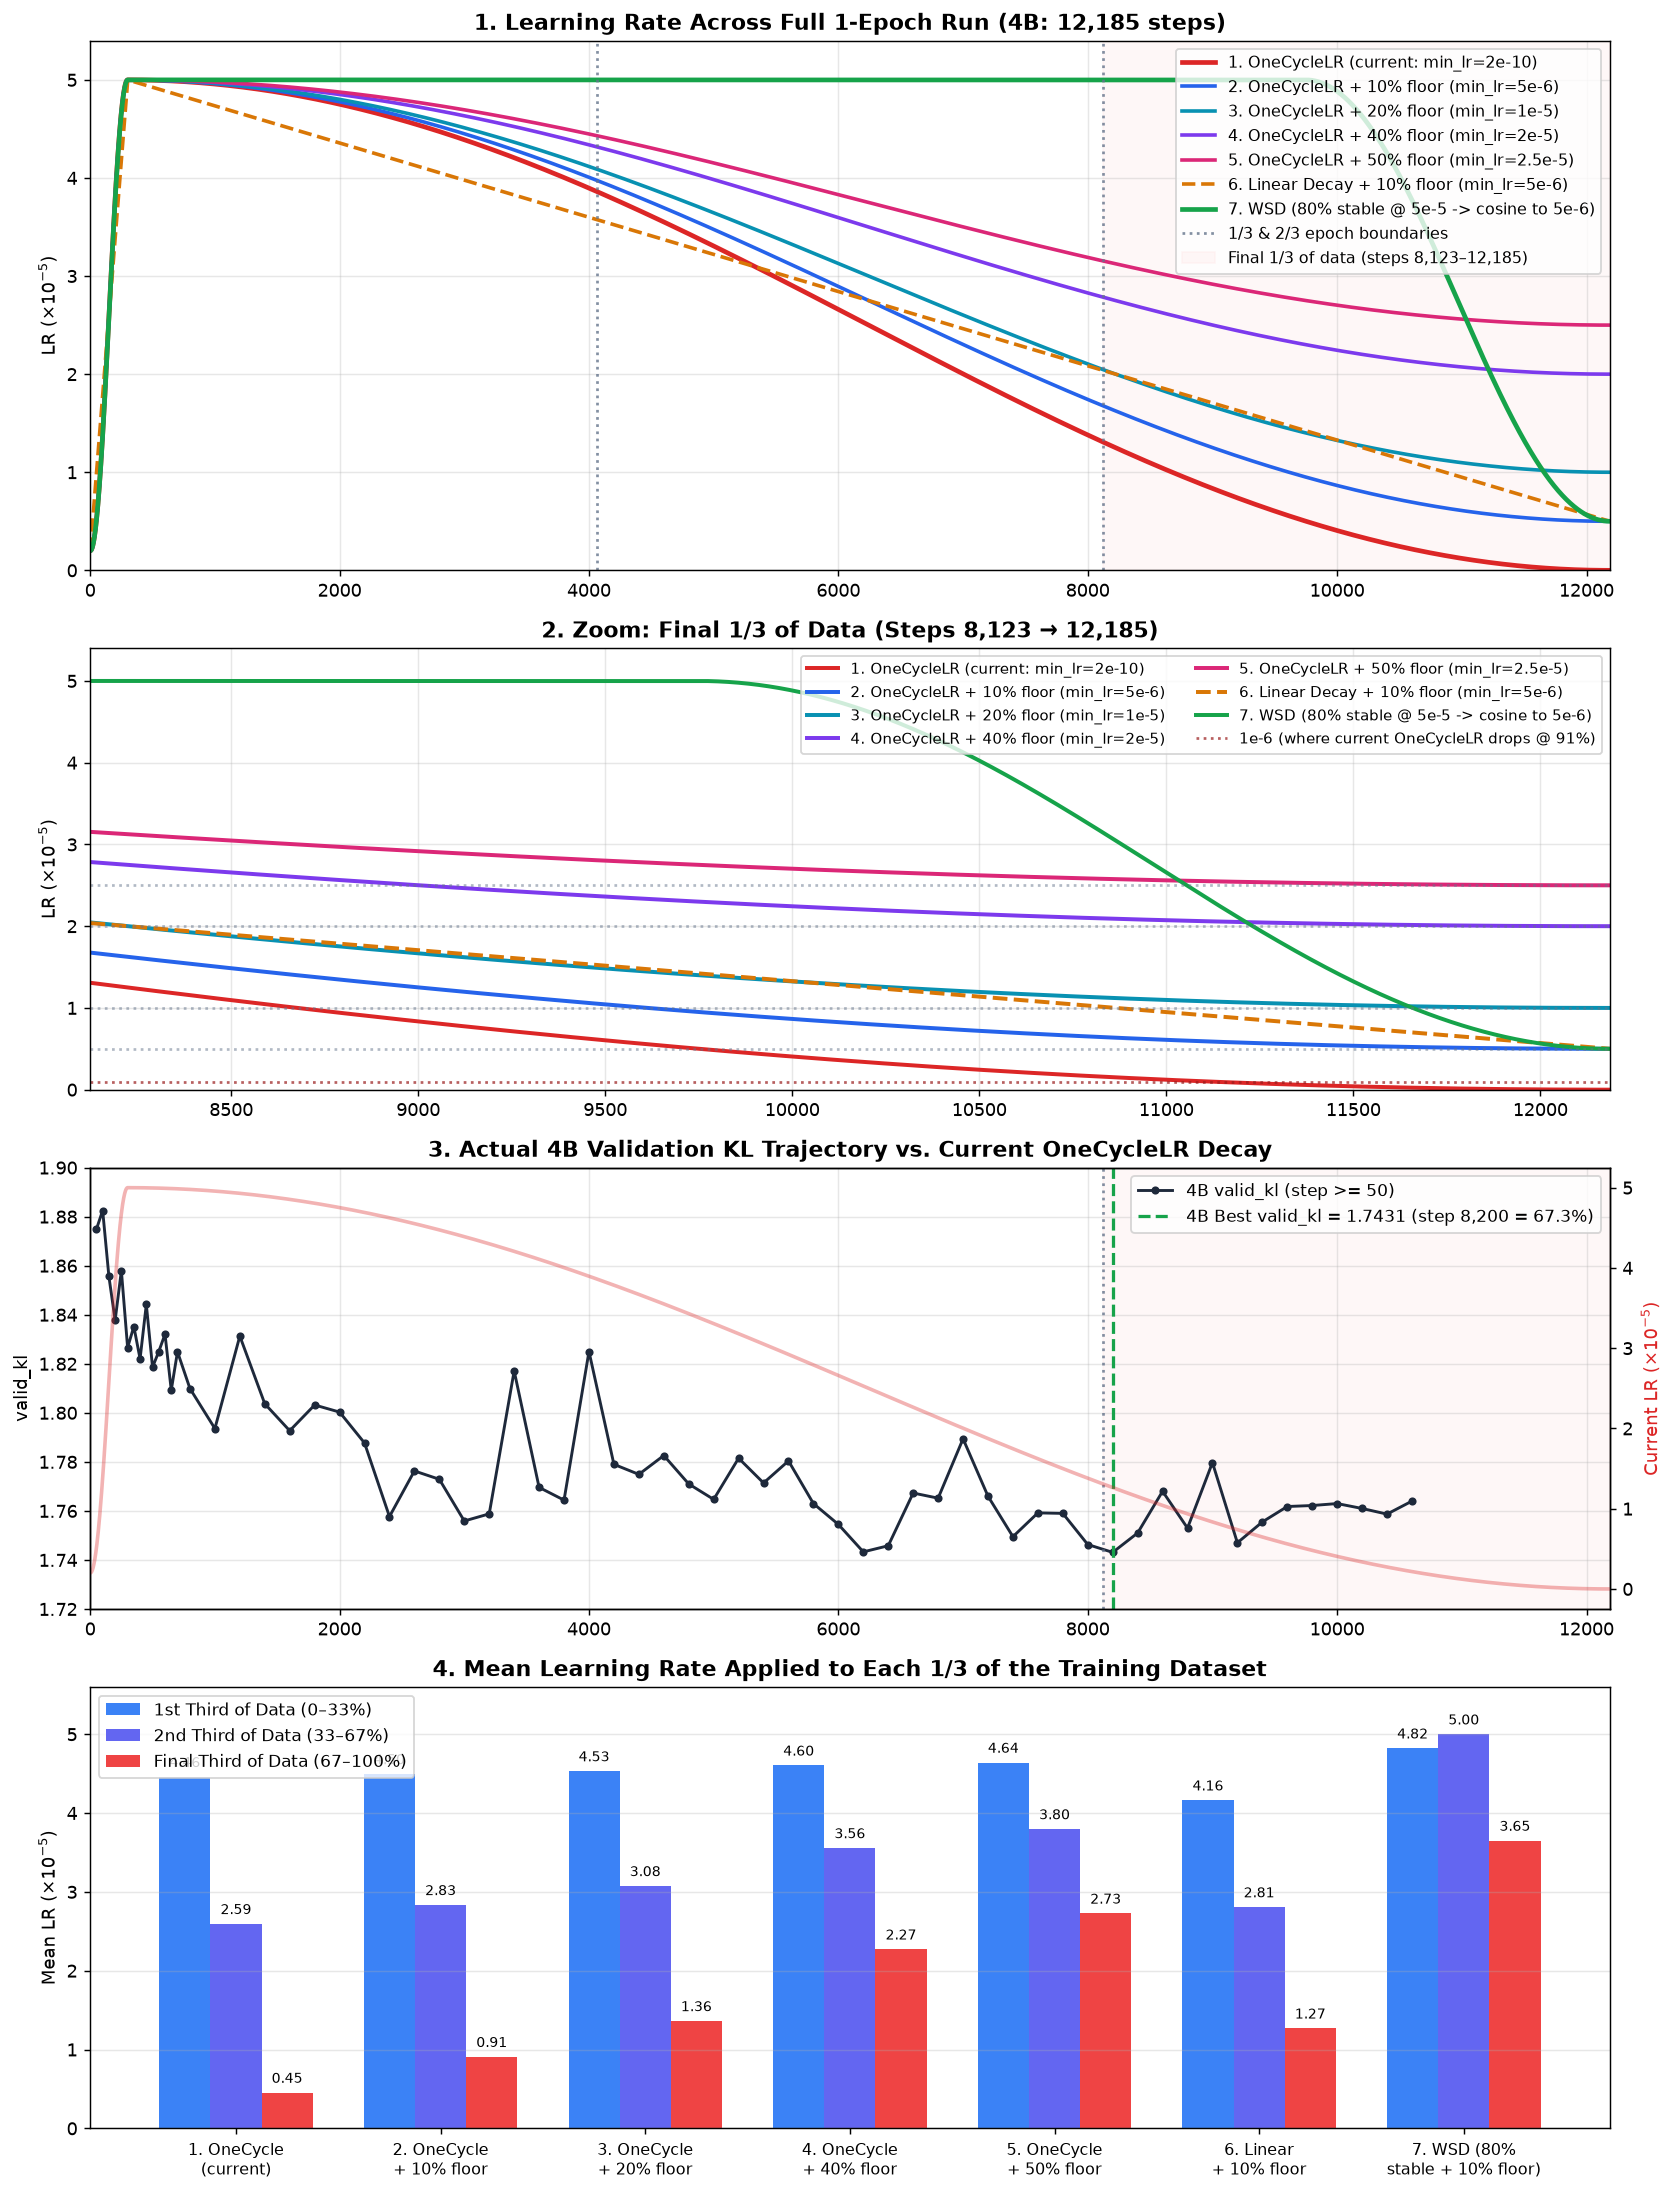

In [3]:
# Actual 4B validation trajectory from kev-4b-resp-issp+twin2k-grouped-newvalid
val_4b_steps = [
    0, 50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600, 650, 700, 800, 1000,
    1200, 1400, 1600, 1800, 2000, 2200, 2400, 2600, 2800, 3000, 3200, 3400, 3600, 3800,
    4000, 4200, 4400, 4600, 4800, 5000, 5200, 5400, 5600, 5800, 6000, 6200, 6400, 6600,
    6800, 7000, 7200, 7400, 7600, 7800, 8000, 8200, 8400, 8600, 8800, 9000, 9200, 9400,
    9600, 9800, 10000, 10200, 10400, 10600
]
val_4b_kls = [
    2.3586, 1.8749, 1.8825, 1.8556, 1.8377, 1.8580, 1.8266, 1.8352, 1.8220, 1.8442, 1.8186,
    1.8250, 1.8321, 1.8092, 1.8249, 1.8099, 1.7936, 1.8313, 1.8037, 1.7927, 1.8032, 1.8003,
    1.7877, 1.7577, 1.7763, 1.7729, 1.7559, 1.7588, 1.8171, 1.7696, 1.7644, 1.8250, 1.7790,
    1.7749, 1.7826, 1.7710, 1.7647, 1.7815, 1.7714, 1.7804, 1.7630, 1.7545, 1.7433, 1.7458,
    1.7673, 1.7652, 1.7894, 1.7660, 1.7495, 1.7592, 1.7590, 1.7463, 1.7431, 1.7510, 1.7680,
    1.7530, 1.7797, 1.7470, 1.7555, 1.7618, 1.7622, 1.7630, 1.7610, 1.7587, 1.7640
]

colors = [
    "#dc2626",  # red: current OneCycleLR (0% floor)
    "#2563eb",  # blue: OneCycleLR + 10% floor (5e-6)
    "#0891b2",  # cyan: OneCycleLR + 20% floor (1e-5)
    "#7c3aed",  # purple: OneCycleLR + 40% floor (2e-5)
    "#db2777",  # pink: OneCycleLR + 50% floor (2.5e-5)
    "#d97706",  # amber: Linear + 10% floor
    "#16a34a",  # green: WSD 80% stable + 10% floor
]

fig, axes = plt.subplots(4, 1, figsize=(13, 17), gridspec_kw={"height_ratios": [1.2, 1.0, 1.0, 1.0]})

# --- Panel 1: Full Epoch LR Schedule ---
ax = axes[0]
for (name, lrs), c in zip(schedules.items(), colors):
    lw = 2.6 if ("current" in name or "WSD" in name) else 2.0
    ls = "--" if "Linear" in name else "-"
    ax.plot(steps, lrs * 1e5, label=name, color=c, linewidth=lw, linestyle=ls)
ax.axvline(t1, color="#64748b", linestyle=":", alpha=0.8, label="1/3 & 2/3 epoch boundaries")
ax.axvline(t2, color="#64748b", linestyle=":", alpha=0.8)
ax.axvspan(t2, TOTAL_STEPS, color="#fee2e2", alpha=0.25, label="Final 1/3 of data (steps 8,123–12,185)")
ax.set_title("1. Learning Rate Across Full 1-Epoch Run (4B: 12,185 steps)", fontsize=12, fontweight="bold")
ax.set_ylabel("LR ($\\times 10^{-5}$)")
ax.set_xlim(0, TOTAL_STEPS)
ax.set_ylim(0, 5.4)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right", fontsize=9)

# --- Panel 2: Zoom on Final Third of Training Data ---
ax2 = axes[1]
for (name, lrs), c in zip(schedules.items(), colors):
    ls = "--" if "Linear" in name else "-"
    ax2.plot(steps[t2:], lrs[t2:] * 1e5, label=name, color=c, linewidth=2.2, linestyle=ls)
for pct_floor, y_val in [(10, 0.5), (20, 1.0), (40, 2.0), (50, 2.5)]:
    ax2.axhline(y_val, color="#64748b", linestyle=":", alpha=0.5)
ax2.axhline(0.1, color="#991b1b", linestyle=":", alpha=0.7, label="1e-6 (where current OneCycleLR drops @ 91%)")
ax2.set_title("2. Zoom: Final 1/3 of Data (Steps 8,123 → 12,185)", fontsize=12, fontweight="bold")
ax2.set_ylabel("LR ($\\times 10^{-5}$)")
ax2.set_xlim(t2, TOTAL_STEPS)
ax2.set_ylim(0, 5.4)
ax2.grid(True, alpha=0.3)
ax2.legend(loc="upper right", fontsize=8.5, ncol=2)

# --- Panel 3: Actual 4B valid_kl vs Current OneCycleLR ---
ax3 = axes[2]
ax3.plot(val_4b_steps[1:], val_4b_kls[1:], marker="o", markersize=3.5, color="#1e293b", linewidth=1.6, label="4B valid_kl (step >= 50)")
ax3.axvline(8200, color="#16a34a", linestyle="--", linewidth=1.8, label="4B Best valid_kl = 1.7431 (step 8,200 = 67.3%)")
ax3.axvline(t2, color="#64748b", linestyle=":", alpha=0.8)
ax3.axvspan(t2, TOTAL_STEPS, color="#fee2e2", alpha=0.25)
ax3_lr = ax3.twinx()
ax3_lr.plot(steps, schedules["1. OneCycleLR (current: min_lr=2e-10)"] * 1e5, color="#dc2626", alpha=0.35, linewidth=2.0, label="Current OneCycleLR")
ax3_lr.set_ylabel("Current LR ($\\times 10^{-5}$)", color="#dc2626")
ax3.set_title("3. Actual 4B Validation KL Trajectory vs. Current OneCycleLR Decay", fontsize=12, fontweight="bold")
ax3.set_ylabel("valid_kl")
ax3.set_xlim(0, TOTAL_STEPS)
ax3.set_ylim(1.72, 1.90)
ax3.grid(True, alpha=0.3)
ax3.legend(loc="upper right", fontsize=9.5)

# --- Panel 4: Mean Effective LR Received by Each Third of the Dataset ---
ax4 = axes[3]
x = np.arange(len(schedules))
width = 0.25
first_means = [lrs[:t1].mean() * 1e5 for lrs in schedules.values()]
second_means = [lrs[t1:t2].mean() * 1e5 for lrs in schedules.values()]
third_means = [lrs[t2:].mean() * 1e5 for lrs in schedules.values()]

b1 = ax4.bar(x - width, first_means, width, label="1st Third of Data (0–33%)", color="#3b82f6")
b2 = ax4.bar(x, second_means, width, label="2nd Third of Data (33–67%)", color="#6366f1")
b3 = ax4.bar(x + width, third_means, width, label="Final Third of Data (67–100%)", color="#ef4444")
for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width() / 2, h + 0.08, f"{h:.2f}", ha="center", va="bottom", fontsize=8)

short_labels = [
    "1. OneCycle\n(current)",
    "2. OneCycle\n+ 10% floor",
    "3. OneCycle\n+ 20% floor",
    "4. OneCycle\n+ 40% floor",
    "5. OneCycle\n+ 50% floor",
    "6. Linear\n+ 10% floor",
    "7. WSD (80%\nstable + 10% floor)",
]
ax4.set_xticks(x)
ax4.set_xticklabels(short_labels, fontsize=9)
ax4.set_ylabel("Mean LR ($\\times 10^{-5}$)")
ax4.set_ylim(0, 5.6)
ax4.set_title("4. Mean Learning Rate Applied to Each 1/3 of the Training Dataset", fontsize=12, fontweight="bold")
ax4.grid(True, axis="y", alpha=0.3)
ax4.legend(loc="upper left", fontsize=9.5)

fig.tight_layout()
plt.show()